## Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
pd.set_option('display.max_columns', None)

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
df.shape

(2443651, 9)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [13]:
num = df[['stars', 'reviews', 'price', 'boughtInLastMonth']]
cat = df[['uid', 'asin', 'title','category']]
round(num.describe(), 2)

,stars,reviews,price,boughtInLastMonth
count,2443651.00,2443651.00,2443651.00,2443651.00
mean,2.15,480.63,89.24,25.90
std,2.19,5944.12,345.61,240.48
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,9.99,0.00
50%,0.00,0.00,19.09,0.00
75%,4.40,59.00,45.99,0.00
max,5.00,1356658.00,100000.00,50000.00


In [18]:
for column in cat:
    print(df[column].value_counts())

uid
1          1
1833462    1
1833464    1
1833465    1
1833466    1
          ..
889449     1
889450     1
889451     1
889452     1
2828593    1
Name: count, Length: 2443651, dtype: int64
asin
B083L94P36    7
B08CS1RJYK    7
B07MVP6T9C    7
B0884G1PZ5    7
B08BDG1DR2    7
             ..
B004BW8TYC    1
B0BPMBYBKL    1
B0BV24Z9M4    1
B08NVLFT7M    1
B08P3W9B3T    1
Name: count, Length: 2222742, dtype: int64
title
OYhmc Portable Pedal Exerc                                                                                                                                                                        723
ScibOr Outdoor Sleeveless Fishing Vest                                                                                                                                                            322
SHOPPRO Kids Golf Shoes Set, White, with Shoes Bag, UV Sun Protection Arm Sleeves, Golf Pro Cap and Instant Cooling Towel, Outdoor Sneakers, Girls Sport Training, POSMA GSH007WHT39_B (

### Frequency tables:

In [19]:
frequency_table = df.category.value_counts()
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

Top 5 most listed categories are: 
* Sports & Outdoors
* Beauty
* Handmate Clothing, Shoes & Accessories
* Bath & Body
* Birthday Gifts

Sports & Outdoors is by far the biggest category on Amazon. With over 835k items listed in Amazon's catalogue. This is folowed by Beauty, Handmade and Bath&Body and Birthday gifts. These categories have listings in a similar frequency around 18k/19k items in the category. 

### Visualization

In [23]:
categories = ['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories', 'Bath & Body', 'Birthday Gifts']
top_5 = df[df['category'].isin(categories)]
top_5

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82165,89485,B08G2HBBB6,GoPro HERO9 - Waterproof Sports Camera with Fr...,4.5,5161,199.00,True,0,Sports & Outdoors
82166,89486,B09D15SFMQ,GoPro HERO10 Black - Waterproof Action Camera ...,4.4,2467,249.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


In [24]:
top_5b = top_5[top_5['boughtInLastMonth'] >= 1 ]
top_5b

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82177,89497,B07768BFPY,"LONDON FAB Waterproof Chest Mount, Harness, St...",4.4,2187,9.99,False,200,Sports & Outdoors
82189,89509,B0CDWNXQ4H,"8PCS Dash Cam Sticky Pads, 3M Sticky Pads Adhe...",5.0,1,4.99,False,50,Sports & Outdoors
82191,89511,B012UOXKQ4,PROtastic Curved Sticky Adhesive Spare Replace...,4.4,607,6.99,False,100,Sports & Outdoors
82198,89518,B078XXNPSD,"CatEye CA5445340 Gopro Light Bracket Adapter, ...",4.3,881,6.99,False,100,Sports & Outdoors
82233,89553,B0756SFRG3,StylishDevice Chest Mount Harness Strap + J-Ho...,4.2,319,7.99,False,50,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2129482,2464119,B08XJDWX9G,"10Pcs Mini Carabiner Clips Paracord Keychain, ...",4.5,51,3.99,False,50,Sports & Outdoors
2129485,2464135,B093267T31,POWER GUIDANCE Rock Climbing Hangboard Wood Cl...,4.2,42,47.19,False,50,Sports & Outdoors
2129486,2464138,B0BX637YCJ,Guryon Ultralight Outdoor Folding Camping Tabl...,3.8,15,19.99,False,50,Sports & Outdoors
2129508,2464264,B0CF833DJF,"15pcs Zipper Clip Theft Deterrent, Zipper Pull...",0.0,0,5.99,False,50,Sports & Outdoors


In [30]:
top_5bs = top_5b[top_5b['isBestSeller'] == True ]
top_5bs
top_5bs_sort = top_5bs.sort_values('boughtInLastMonth', ascending=False)

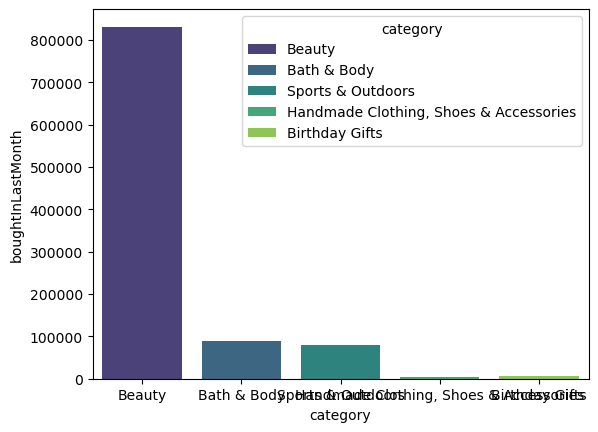

In [33]:
sns.barplot(
    x='category',
    y='boughtInLastMonth',
    data=top_5bs_sort,
    hue='category',
    palette='viridis',
    legend=True,
    errorbar=None,
    estimator='sum'
)
plt.show()

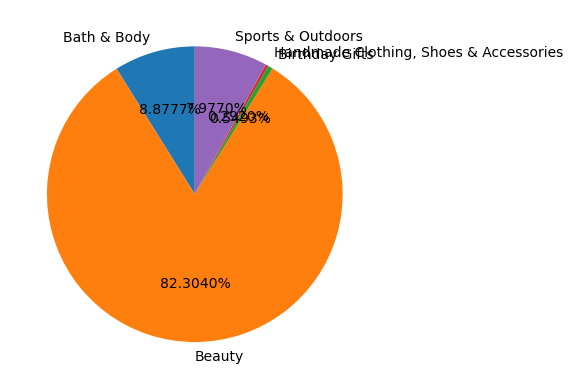

In [39]:
plot_data = top_5bs_sort.groupby('category')['boughtInLastMonth'].sum().reset_index()
plt.pie(plot_data['boughtInLastMonth'], labels=plot_data['category'], autopct='%1.4f%%', startangle=90)
plt.show()

### Product categories

Even though Sports & Outdoors have the most listings in the categories of Amazon. the category 'Beauty' has by far the most items sold last month. 82% of the items bought come from the category Beauty. 

# Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

### 1. Measures of Centrality

In [40]:
price_mean, price_median, price_mode = df['price'].mean(), df['price'].median(), df['price'].mode()[0]
print(f"Mean:{price_mean}")
print(f"Median:{price_median}")
print(f"Mode:{price_mode}")

Mean:89.24380943923661
Median:19.09
Mode:9.99


The mean, median and mode for the price of products are: 
* Mean: 89.24380943923661
* Median: 19.09
* Mode: 9.99

In [41]:
round(df['price'].describe(), 3)

count    2443651.000
mean          89.244
std          345.609
min            0.000
25%            9.990
50%           19.090
75%           45.990
max       100000.000
Name: price, dtype: float64

The average price point of the products listed is 89.24. However the most common price is 9.99. This shows that there are a few outliers on the higher end of the price range. Since the difference is almost 10x. 

### 2. Measures of Dispersion


In [71]:
round(df['price'].var(), 3)

119445.485

In [73]:
Q3 = np.quantile(df['price'], 0.75)
Q1 = np.quantile(df['price'], 0.25)
IQR = Q3 - Q1
IQR_rounded = round(IQR, 3)
IQR_rounded

np.float64(36.0)

The prices vary a lot the difference between the lowest and highest price is 100k. 
With quite a high standard deviation, shows that the different price ranges are highly spreaded. However 75% of the prices are below 45.99. Which means there are some outliers in the highest 25% of the price range. 

### 3. Visualisations

In [43]:
q75 = df['price'].quantile(0.75)
subset_75 = df[df['price'] < q75]

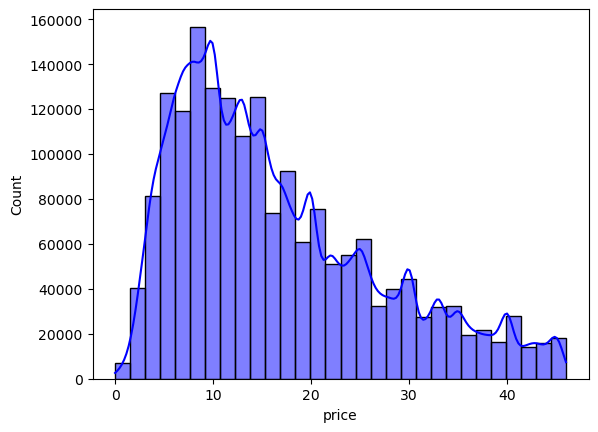

In [45]:
sns.histplot (data=subset_75, x='price', bins=30, kde=True, color='blue')
plt.show()

Most products in the catalogue are between 5 - 15 pound. With the majority of the prices arount 9 pound. 

<Axes: xlabel='price', ylabel='category'>

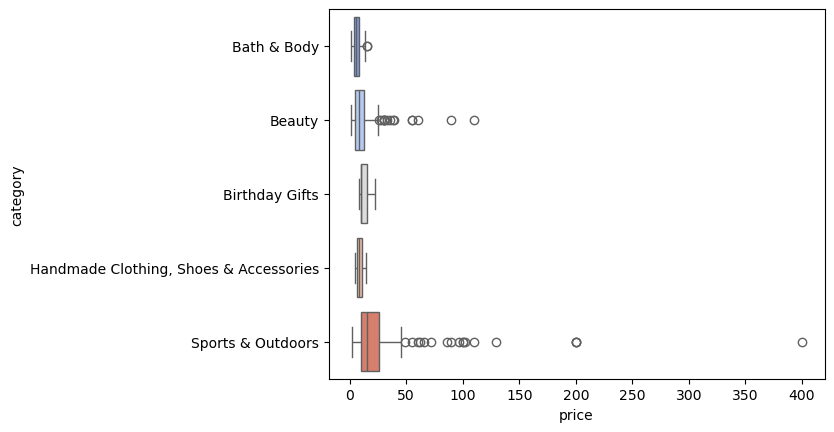

In [51]:
sns.boxplot(data=top_5bs, x='price', y='category',hue='category', palette='coolwarm', legend=False)

In [55]:
df.nlargest(5,'price')

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
2008013,2259336,B091F5Y3CT,HB FBA Test Treadmill,0.0,0,100000.00,False,0,Sports & Outdoors
1987238,2235317,B0CDVKNBRV,Générique L.A 350° - I5 11400F - RTX 3050 8G -...,0.0,0,77752.00,False,0,Desktop PCs
1905315,2136904,B0CJSNFYVM,Abaodam decor christmas ornaments Desk Ornamen...,0.0,0,24674.59,False,0,Garden Storage & Housing
1408966,1551117,B0CHT331TN,BM4445-FI1-01200R10-03-E03 Driver,0.0,0,23482.73,False,0,Scanners & Accessories
319555,340285,B0CHYG6MNW,HEDUSA Halloween 3D Holographic Fan 3D Hologra...,0.0,0,22933.42,False,0,Projectors


I used the boxplot to look for outliers within the top 5 categories of Amazon. The boxplot shows that there are quite some outliers in Sports & Outdoors. However there are also quite some outliers in Beauty, however the difference here is not as big as in Sports & Outdoors. 
Out of curiosity I wanted to see what the 5 most expensive items were. And it seems that the highest priced product is a test product, with the price of 100.000. For al 5 products with the highest price, aren't any sales last month. 

To answer the Business Question: The majority of the products are priced fair, between the 5 and 15 pound. Most common price in the top 5 categories, of most listing, where the items were bought more than 1x last month and is considered a BestSeller is: 9,-

# Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?



### 1. Measures of Centrality

In [59]:
df2 = df[df['boughtInLastMonth'] > 0]

stars_mean, stars_median, stars_mode = df2['stars'].mean(), df2['stars'].median(), df2['stars'].mode()[0]
print(f"Mean:{stars_mean}")
print(f"Median:{stars_median}")
print(f"Mode:{stars_mode}")

Mean:4.361374486406461
Median:4.5
Mode:4.5


The mean, median and mode for the rating of products is: 
* Mean:4.361374486406461
* Median:4.5
* Mode:4.5

This shows that in general the customers rate the products very high in general. The products are rated on average 4.4 stars and the most common rating is 4.5 stars. 

## 2. Measures of Dispersion

In [63]:
round(df2['stars'].describe(), 3)

count    213447.000
mean          4.361
std           0.513
min           0.000
25%           4.300
50%           4.500
75%           4.600
max           5.000
Name: stars, dtype: float64

In [66]:
round(df2['stars'].var(), 3)

0.264

In [69]:
Q3 = np.quantile(df2['stars'], 0.75)
Q1 = np.quantile(df2['stars'], 0.25)
IQR = Q3 - Q1
IQR_rounded = round(IQR, 3)
IQR_rounded


np.float64(0.3)

These are the measures of dispersion for rating: 
* Variance: 0.264
* Standard deviation: 0.513
* interquartile range: 0.3

These ratings are quite consistent, as the ratings vary 0.26 stars from the mean. They do however lean towards the higher values of the ratings. 

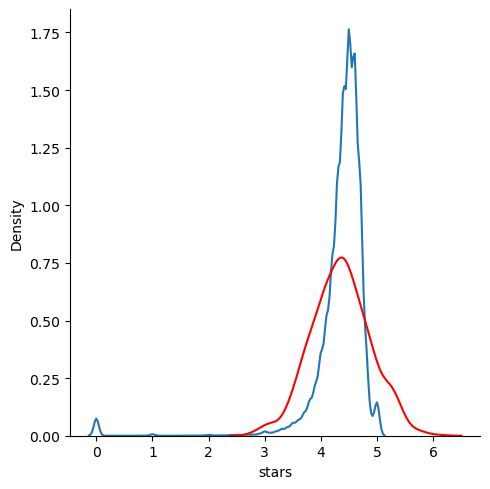

In [79]:
sns.displot(df2['stars'], kind='kde', label='Actual data')
std = df2['stars'].std()
x = np.linspace(df2['stars'].min(), df2['stars'].max(), 100)
normal_dist = np.random.normal(stars_mean, std, 1000)
sns.kdeplot(normal_dist, color='red', label='Normal distribution')
plt.show()

In [80]:
#skewness
df2['stars'].skew()

np.float64(-5.544486225105293)

The skewness of the rating is -5.54, which means that the distribution is negatively skewed. With a longer tail on the left side, the bulk of the data is concentrated on the right. Which is very obvious in the graph above. 

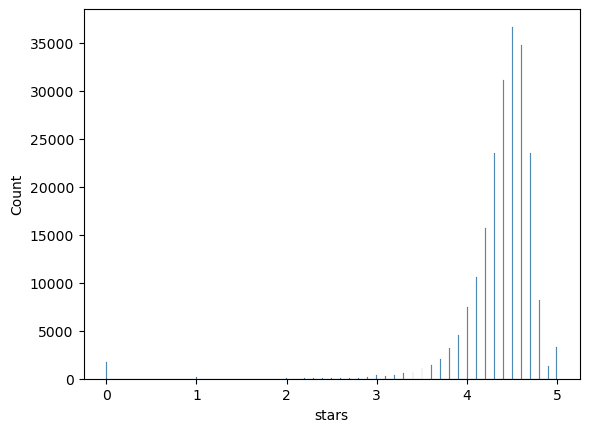

In [84]:
sns.histplot(df2.stars, bins="auto")
plt.show()

The histogram clearly shows that the most common rating 4.5 is. 